## 1. Imports

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/processed/microsoft_model_ready.csv")

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

df.head()

,Date,Open,High,Low,Close,Volume,Year,Month,DayOfWeek,Daily_Return,Close_Lag_1,Close_Lag_5,Close_Lag_10,MA_7,MA_20,MA_50,Target_Next_Close
0,2015-06-11 16:00:00,46.66,46.92,46.13,46.44,27347758,2015,6,3,-0.364729,46.61,46.36,47.45,46.254286,47.0475,45.6266,45.97
1,2015-06-12 16:00:00,46.20,46.47,45.90,45.97,23930972,2015,6,4,-1.012059,46.44,46.14,46.86,46.128571,46.9100,45.7316,45.48
2,2015-06-15 16:00:00,45.45,45.65,45.02,45.48,33254517,2015,6,0,-1.065913,45.97,45.73,47.23,46.002857,46.7690,45.8354,45.83
3,2015-06-16 16:00:00,45.35,46.24,45.30,45.83,27070306,2015,6,1,0.769569,45.48,45.65,46.92,45.958571,46.6600,45.9210,45.97
4,2015-06-17 16:00:00,45.73,46.07,45.36,45.97,28704061,2015,6,2,0.305477,45.83,46.61,46.85,45.992857,46.5795,46.0098,46.72


## 2. Select features and target

In [59]:
features = [
    "Open", "High", "Low", "Close", "Volume",
    "Year", "Month", "DayOfWeek",
    "Daily_Return",
    "Close_Lag_1", "Close_Lag_5", "Close_Lag_10",
    "MA_7", "MA_20", "MA_50"
]

X = df[features]
y = df["Target_Next_Close"]

## 3. Split Dataset

In [60]:
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1168
Testing samples: 293


## 4. Conduct training and comaprisons

In [61]:
# Experiment 0: Baseline
baseline_predictions = X_test["Close"].values

# Experiment 1: Random Forest
rf1 = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

rf1.fit(X_train, y_train)
rf1_predictions = rf1.predict(X_test)

# Experiment 2: Hyperparameter tuning
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10],
    "min_samples_leaf": [2, 5]
}

tscv = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Experiment 3: Ridge Regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

## 5. Model Evaluation

In [62]:
models = {
    "Naive Baseline": X_test["Close"].values,
    "Random Forest": rf1_predictions,
    "Tuned Random Forest": rf2_predictions,
    "Ridge Regression": ridge_predictions
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))
best_model = grid_search.best_estimator_
rf2_predictions = best_model.predict(X_test)

print("Best parameters:", grid_search.best_params_)

                 Model      MAE     RMSE      R2
0       Naive Baseline   3.4128   4.7012  0.9645
1        Random Forest  38.4303  43.9079 -2.0940
2  Tuned Random Forest  36.6976  42.1943 -1.8572
3     Ridge Regression   3.7011   4.8914  0.9616
Best parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 100}


## 6. Visualizations

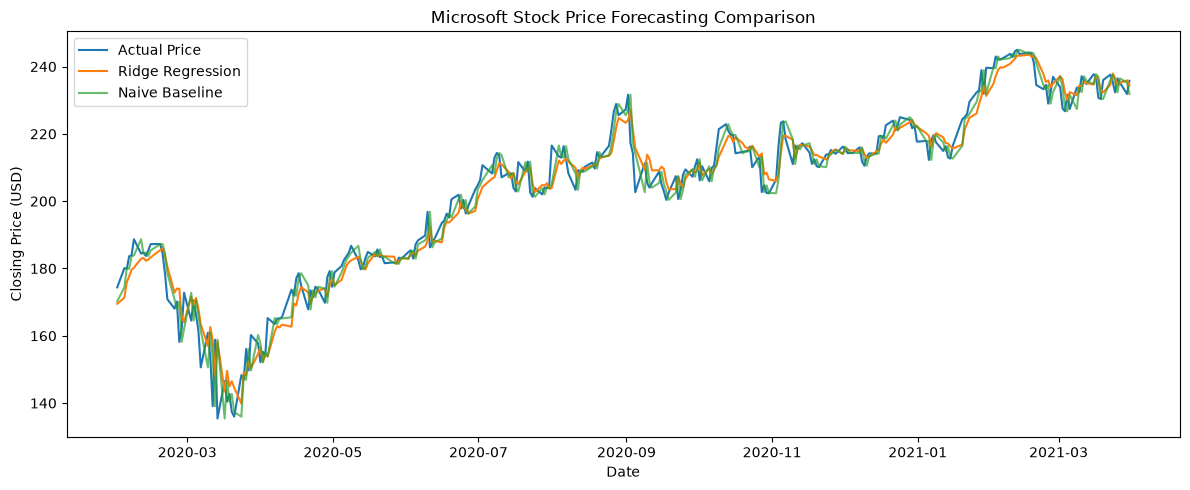

In [63]:
plt.figure(figsize=(12, 5))

dates = df["Date"].iloc[split:]

plt.plot(dates, y_test, label="Actual Price")
plt.plot(dates, ridge_predictions, label="Ridge Regression")
plt.plot(dates, X_test["Close"], label="Naive Baseline", alpha=0.7)

plt.title("Microsoft Stock Price Forecasting Comparison")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Errors

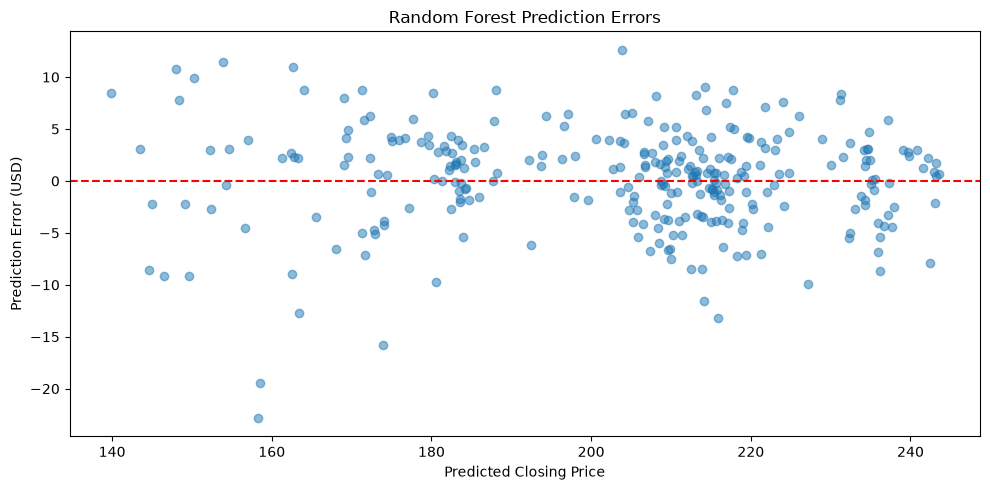

In [64]:
errors = y_test.values - ridge_predictions

plt.figure(figsize=(10, 5))

plt.scatter(ridge_predictions, errors, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.title("Random Forest Prediction Errors")
plt.xlabel("Predicted Closing Price")
plt.ylabel("Prediction Error (USD)")
plt.tight_layout()
plt.show()

## 8. Saving results and model

In [67]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

joblib.dump(ridge_model, "../models/model.joblib")
joblib.dump(features, "../models/feature_columns.joblib")
print("Model saved successfully!")

Path("../outputs").mkdir(exist_ok=True)

results_df.to_csv("../outputs/experiments.csv", index=False)

Model saved successfully!
